# Create additional figures 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

## Iterative initial frequency refinement

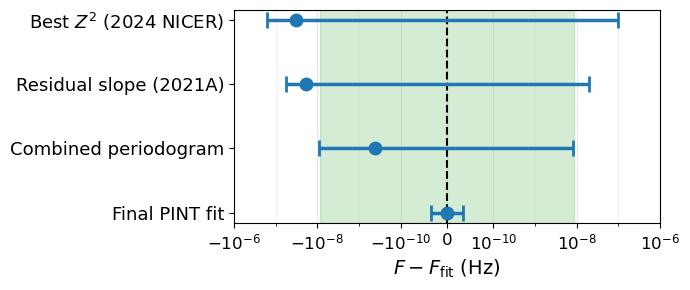

In [56]:
# Data
labels = [
    #r"Existing measurement",
    r"Best $Z^2$ (2024 NICER)",
    r"Residual slope (2021A)",
    r"Combined periodogram",
    r"Final PINT fit",
]
# freqs = np.array([0.0337725, 0.03377270, 0.033772714, 0.0337727321, 0.03377273252])
# uncerts = np.array([3e-7, 1.3e-7, 3.8e-8, 8.8e-9, 3.4e-11])
freqs = np.array([0.03377270, 0.033772714, 0.0337727321, 0.03377273252])
uncerts = np.array([1.3e-7, 3.8e-8, 8.8e-9, 3.4e-11])

F_final = freqs[-1]
delta_f = 8.5e-9  # max tolerable frequency error

# Offsets from final fit
offsets = freqs - F_final

# Plot
fig, ax = plt.subplots(figsize=(7, 3))

# Shaded band for max tolerable error
ax.axvspan(-delta_f, delta_f, color="C2", alpha=0.2, label=r"Max tolerable $\Delta f$")

# Reference line at x=0
ax.axvline(0, color="k", linestyle="--", linewidth=1.5)

# Horizontal error bars (step 1 at top → y=3, step 4 at bottom → y=0)
y_pos = np.arange(len(labels))[::-1]
ax.errorbar(offsets, y_pos, xerr=uncerts, fmt="o", color="C0",
            capsize=6, capthick=2, markersize=9, linewidth=2.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=13)
ax.set_xlabel(r"$F - F_{\mathrm{fit}}$ (Hz)", fontsize=14)
ax.set_xscale("symlog", linthresh=1e-10)

# Only label powers of 10 at every other decade to reduce crowding
import matplotlib.ticker as ticker
major_ticks = [0] + [s * 10**e for e in range(-10, -5, 2) for s in (1, -1)]
ax.xaxis.set_major_locator(ticker.FixedLocator(major_ticks))
ax.xaxis.set_major_formatter(ticker.LogFormatterSciNotation(linthresh=1e-11))

ax.tick_params(axis="x", labelsize=12)
ax.set_xlim(-1e-6, 1e-6)
ax.grid(axis="x", alpha=0.3, which="major")
ax.grid(axis="x", alpha=0.15, which="minor")
fig.tight_layout()

# Save
savedir = "../paper_figures"
os.makedirs(savedir, exist_ok=True)
fig.savefig(f"{savedir}/initial_frequency_plot.pdf", bbox_inches="tight", dpi=300)
plt.show()

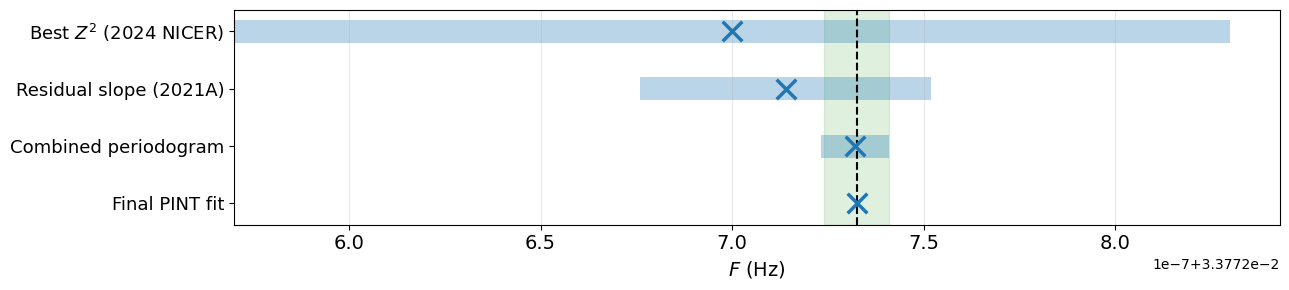

In [69]:
# Plot v2: raw frequencies, larger fonts/markers/lines, smaller figure
fig, ax = plt.subplots(figsize=(13, 3))

# Shaded band around final fit value
ax.axvspan(F_final - delta_f, F_final + delta_f, color="C2", alpha=0.15,
           label=r"Max tolerable $\Delta f$")

# Reference line at final fit frequency
ax.axvline(F_final, color="k", linestyle="--", linewidth=1.5)

# Horizontal error bars as shaded bars + x markers
y_pos = np.arange(len(labels))[::-1]
bar_height = 0.4
for i in range(len(labels)):
    ax.barh(y_pos[i], width=2*uncerts[i], left=freqs[i]-uncerts[i],
            height=bar_height, color="C0", alpha=0.3)
ax.scatter(freqs, y_pos, marker="x", color="C0", s=200, zorder=5, linewidths=2.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=13)
ax.set_xlabel(r"$F$ (Hz)", fontsize=14)
ax.tick_params(axis="x", labelsize=14)
#ax.legend(loc="upper left", fontsize=12)
#ax.set_xlim(0.03377273, 0.03377274)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()

savedir = "../paper_figures"
fig.savefig(f"{savedir}/initial_frequency_plot.pdf", bbox_inches="tight", dpi=300)
plt.show()